# A. Linear power-spectrum emulators: accuracy and speed

This notebook follows Appendix A of Paper I, which redoes Fig. 10 of Sui et al. (2025) with `emu_pk` in it.
Each emulator is scored by the mean of $|P/P_{\rm true}-1|$ over 200 wavenumbers log-spaced in $[0.009, 9]\,h\,{\rm Mpc}^{-1}$ at $z = 0$, and timed for one evaluation at $z = 1$, at the four Quijote cosmologies.
We recompute `emu_pk`'s errors and time it on this machine; the other codes need their own environments, so their errors and timings, and the CLASS and CAMB spectra used as truths, come from the tutorial data bundle.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

import json
import time

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from emu_pk import PkEmulator

load = lambda name: json.load(open(T.data_path(name)))

ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = False


## The four cosmologies and the two truths

Fid has $\Omega_{\rm m} = 0.3175$, $\Omega_{\rm b} = 0.049$, $h = 0.6711$, $n_{\rm s} = 0.9624$, $\sigma_8 = 0.834$, $w = -1$ and massless neutrinos.
$w^\pm$ change only $w$, to $-0.95$ and $-1.05$, at the same $\sigma_8$.
$M_\nu^+$ adds $\sum m_\nu = 0.1$ eV in three equal masses at the $A_{\rm s}$ and $\Omega_{\rm m}$ of Fid.
The first truth is CLASS 3.3.4 at its default precision, set up as Sui et al. (2025) do; the second is converged CLASS.

In [2]:
cos = load("emulators/cosmologies.json")
truth = np.load(T.data_path("emulators/truth.npz"))
ref = np.load(T.data_path("emulators/ref.npz"))
K = np.logspace(np.log10(9e-3), np.log10(9.0), 200)
assert np.allclose(truth["k"], K)
for name, cc in cos.items():
    print(f"{name:5s} " + "  ".join(f"{k}={v:.4g}" for k, v in cc.items()))

Fid   Om=0.3175  Ob=0.049  h=0.6711  ns=0.9624  mnu=0  w0=-1  wa=0  As=2.134e-09  sigma8=0.834
Mnu+  Om=0.3175  Ob=0.049  h=0.6711  ns=0.9624  mnu=0.1  w0=-1  wa=0  As=2.134e-09  sigma8=0.8108
w+    Om=0.3175  Ob=0.049  h=0.6711  ns=0.9624  mnu=0  w0=-0.95  wa=0  As=2.191e-09  sigma8=0.834
w-    Om=0.3175  Ob=0.049  h=0.6711  ns=0.9624  mnu=0  w0=-1.05  wa=0  As=2.085e-09  sigma8=0.834


## Scoring `emu_pk`

`emu_pk` takes $(\omega_{\rm b}, \omega_{\rm cdm}, h, n_{\rm s}, \ln10^{10}A_{\rm s}, \sum m_\nu, w_0, w_a, \Omega_k)$ and two mass ratios ($1/3$ each for degenerate masses); $\Omega_{\rm m}$ contains the neutrinos' rest mass, $\Omega_\nu h^2 = \sum m_\nu/93.14$ eV.

In [3]:
emu = PkEmulator()


def theta(c):
    ocdm = (c["Om"] - c["Ob"] - c["mnu"] / 93.14 / c["h"] ** 2) * c["h"] ** 2
    return np.array([c["Ob"] * c["h"] ** 2, ocdm, c["h"], c["ns"], np.log(1e10 * c["As"]), c["mnu"],
                     c["w0"], c["wa"], 0.0, 1 / 3, 1 / 3])


err = {n: float(np.mean(np.abs(np.asarray(emu.pk(K, 0.0, theta(c))) / truth[f"class/{n}/0"] - 1))) for n, c in cos.items()}
err_ref = {n: float(np.mean(np.abs(np.asarray(emu.pk(K, 0.0, theta(c))) / ref[n] - 1))) for n, c in cos.items()}
cpu = load("emulators/cpu.json")
print(f"{'':6s}{'vs CLASS default':>18s}{'(bundle)':>10s}{'vs converged':>14s}{'(bundle)':>10s}")
for n in cos:
    print(f"{n:6s}{err[n]:18.2e}{cpu['error_z0']['emu_pk'][n]:10.2e}{err_ref[n]:14.2e}{cpu['error_ref_z0']['emu_pk'][n]:10.2e}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


        vs CLASS default  (bundle)  vs converged  (bundle)
Fid             7.34e-04  7.34e-04      8.25e-04  8.25e-04
Mnu+            2.31e-03  2.31e-03      2.74e-04  2.74e-04
w+              7.31e-04  7.31e-04      8.29e-04  8.29e-04
w-              7.20e-04  7.20e-04      8.19e-04  8.19e-04


At $M_\nu^+$ the default-precision CLASS is itself $2.1\times10^{-3}$ from converged CLASS, so the offset in the first column is that of the truth, not of the emulator.

## Timing

The paper times one core of an Intel Xeon Gold 6244 with one thread, the JAX function compiled, as the mean over 1 000 calls.
A laptop is usually faster.

In [4]:
kj = jnp.asarray(K)
f = jax.jit(lambda th: emu.pk(kj, 1.0, th))
th = jnp.asarray(theta(cos["Fid"]))
f(th).block_until_ready()
n = 200 if FAST else 1000
t0 = time.perf_counter()
for _ in range(n):
    f(th).block_until_ready()
t_here = (time.perf_counter() - t0) / n
print(f"emu_pk on this machine: {1e3 * t_here:.2f} ms;  paper (Xeon Gold 6244): {1e3 * cpu['time_cpu_z1']['emu_pk']:.2f} ms")

emu_pk on this machine: 0.27 ms;  paper (Xeon Gold 6244): 0.42 ms


## The figure

Fig. B.1 of the paper (App. A).
Top: against CLASS at its default precision, the truth of Sui et al. (2025); the dotted vertical is the time of that CLASS.
Bottom: against converged CLASS.
Left: one CPU core.
Right: GPU, in batches of 2 000 (filled) and 20 000 (open), in single precision.

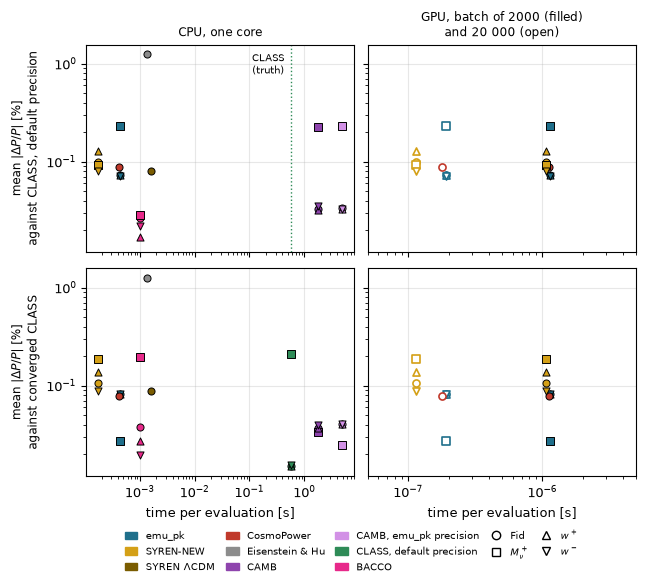

In [5]:
gpu = load("emulators/gpu.json")
ttr = load("emulators/timing_truth.json")
b = load("emulators/bacco_benchmark.json")
COLOURS = {"emu_pk": "#1f6f8b", "SYREN-NEW": "#d4a017", "SYREN LCDM": "#7a5c00", "CosmoPower": "#c0392b",
           "Eisenstein & Hu": "#8c8c8c", "CAMB": "#8e44ad", "CAMB (emu_pk precision)": "#d291e6",
           "CLASS": "#2e8b57", "BACCO": "#e7298a"}
LABELS = {"SYREN LCDM": r"SYREN $\Lambda$CDM", "CAMB (emu_pk precision)": "CAMB, emu_pk precision",
          "CLASS": "CLASS, default precision"}
MARKERS = {"Fid": "o", "Mnu+": "s", "w+": "^", "w-": "v"}
MLAB = {"Fid": "Fid", "Mnu+": r"$M_\nu^+$", "w+": r"$w^+$", "w-": r"$w^-$"}

tcpu = dict(cpu["time_cpu_z1"], **ttr)
tcpu.pop("SYREN-NEW (JAX)")
tgpu = dict(gpu["time_gpu_z1"])
tgpu["SYREN-NEW"] = tgpu.pop("SYREN-NEW (JAX)")
tbig = dict(gpu["time_gpu_z1_batch20000"])
tbig["SYREN-NEW"] = tbig.pop("SYREN-NEW (JAX)")
e0, eref = dict(cpu["error_z0"]), dict(cpu["error_ref_z0"])
e0["BACCO"], eref["BACCO"], tcpu["BACCO"] = b["err_vs_class_default"], b["err_vs_class_converged"], b["cpu_time_s"]

# The style of the script that made the paper's figure: matplotlib's defaults at 9 pt, cropped tight.
plt.rcdefaults()
plt.rcParams.update({"savefig.bbox": "tight", "font.size": 9})
fig, ax = plt.subplots(2, 2, figsize=(7.1, 5.6), sharey=True, sharex="col", gridspec_kw={"wspace": 0.05, "hspace": 0.08})
for r, (errs, lab) in enumerate(((e0, "against CLASS, default precision"), (eref, "against converged CLASS"))):
    for i, times in enumerate((tcpu, tgpu)):
        for name, t in times.items():
            for cname, e in errs.get(name, {}).items():
                ax[r, i].scatter(t, 100 * e, marker=MARKERS[cname], s=26, zorder=3, facecolor=COLOURS[name],
                                 edgecolor="k", lw=0.7)
        ax[r, i].set_xscale("log")
        ax[r, i].grid(alpha=0.3)
    for name, t in tbig.items():
        for cname, e in errs.get(name, {}).items():
            ax[r, 1].scatter(t, 100 * e, marker=MARKERS[cname], s=26, zorder=3, facecolor="white",
                             edgecolor=COLOURS[name], lw=1.2)
    ax[r, 0].set_ylabel(r"mean $|\Delta P/P|$ [%]" + "\n" + lab, fontsize=8.5)
ax[0, 0].set_yscale("log")
ax[0, 0].axvline(ttr["CLASS"], color=COLOURS["CLASS"], ls=":", lw=1)
ax[0, 0].text(ttr["CLASS"] * 0.75, 0.96, "CLASS\n(truth)", ha="right", va="top", fontsize=7,
              transform=ax[0, 0].get_xaxis_transform())
ax[0, 0].set_title("CPU, one core", fontsize=8.5)
ax[0, 1].set_title("GPU, batch of 2000 (filled)\nand 20 000 (open)", fontsize=8.5)
ax[1, 0].set_xlabel("time per evaluation [s]")
ax[1, 1].set_xlabel("time per evaluation [s]")
ax[1, 1].set_xlim(5e-8, 5e-6)
import matplotlib.ticker
ax[1, 1].xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
hand = [Patch(color=COLOURS[nm], label=LABELS.get(nm, nm)) for nm in COLOURS]
hand += [Line2D([], [], ls="", marker=m, mfc="white", mec="k", label=MLAB[cn]) for cn, m in MARKERS.items()]
fig.legend(handles=hand, loc="upper center", bbox_to_anchor=(0.5, 0.03), ncol=5, fontsize=7.5, frameon=False,
           columnspacing=1.0, handlelength=1.2);
T.save_figure(fig, "fig_emulator_benchmark")
T.paper_style()

## Exercises

1. Score `emu_pk` through `ggah_mod` instead (`make_pk("emu_pk")` on a `Cosmology` built from each Quijote cosmology). Which of the two inputs, $\Omega_{\rm m}$ or $\omega_{\rm cdm}$, must you convert, and does the score change?
2. Time the gradient of $\ln P$ with respect to the nine parameters with `jax.jacfwd`. How many spectra does one gradient cost?
3. Batch 2 000 cosmologies with `jax.vmap` and time them on your CPU. How does the time per spectrum compare with one call?